In [71]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
def f(x):
    return 4*x**2 - 3*x + 5

In [ ]:
f(3.0)

In [ ]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)


In [ ]:
# what is the derivate of this function at any point x
# how sensitive is a function to a small change; by how much does it respond, the slope

h = 0.00001
x = 3.0
(f(x + h) - f(x))/h

In [ ]:
# multivariate derivative
h  = 0.0001

#inputs
a = 3.0
b = -2.0
c = 10.0

d1 = a*b + c
a += h
d2 = a*b + c

print( 'd1', d1)
print('d2', d2)
print('slope', (d2 - d1)/h)

In [88]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
        
    def __repr__(self):
        return f"Value(data={self.data})"
    
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        
        return out
    
    def __mul__(self, other): 
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
                
        return out
    
    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out = Value(self.data ** other, (self, ), f'**{other}')
        
        def _backward():
            self.grad += other * (self.data ** (other -1)) * out.grad
        out._backward = _backward
       
        return out
    
    def __rmul__(self, other): # other * self
        return self * other
    
    def __radd__(self, other):
        return self + other
    
    def __rsub__(self, other):
        return other + (-self)
    
    def __truediv__(self, other): # self / other
        return self * other ** -1
    
    def __neg__(self): # -self
        return self * -1
    
    def __sub__(self, other): #self - other
        return self + (-other)
        
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x)+1)
        out = Value(t, (self, ), 'tanh')
        
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        
        return out
    
    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out
    
    def backward(self):
        
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
        
        
    
#forward pass
'''
a = Value(3.0, label= 'a')
b = Value(-2.0, label= 'b')
c = Value(10.0, label= 'c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value((-2.0), label='f')
L = d*f; L.label= 'L'

#(a.__mul__(b)).__add__(c)
#d = a*b + c
#d

L
'''


"\na = Value(3.0, label= 'a')\nb = Value(-2.0, label= 'b')\nc = Value(10.0, label= 'c')\ne = a*b; e.label = 'e'\nd = e + c; d.label = 'd'\nf = Value((-2.0), label='f')\nL = d*f; L.label= 'L'\n\n#(a.__mul__(b)).__add__(c)\n#d = a*b + c\n#d\n\nL\n"

In [ ]:
d._prev

In [ ]:
d._op

In [ ]:
def lol():
    
    h = 0.001
    
    a = Value(3.0, label= 'a')
    b = Value(-2.0, label= 'b')
    c = Value(10.0, label= 'c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value((-2.0), label='f')
    L = d*f; L.label= 'L'
    L1 = L.data
    
    a = Value(3.0, label= 'a')
    b = Value(-2.0, label= 'b')
    c = Value(10.0, label= 'c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value((-2.0), label='f')
    L = d*f; L.label= 'L'
    L2 = L.data + h
    
    print((L2 - L1)/h)

lol()

In [102]:
import os
from graphviz import Digraph
from IPython.display import SVG


graphviz_bin = r'C:\Program Files\Graphviz\bin'
if os.path.isdir(graphviz_bin) and graphviz_bin not in os.environ.get('PATH', ''):
  os.environ['PATH'] = graphviz_bin + os.pathsep + os.environ.get('PATH', '')


def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return SVG(dot.pipe(format='svg').decode('utf-8'))

In [81]:
# so we backprop to get the gradient value , then run the optimization step by running a forward pass of the updated node values that have been nudged in the direction of the gradient

# moving on to building out a simple neuron
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

#weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

#  x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

o.backward()



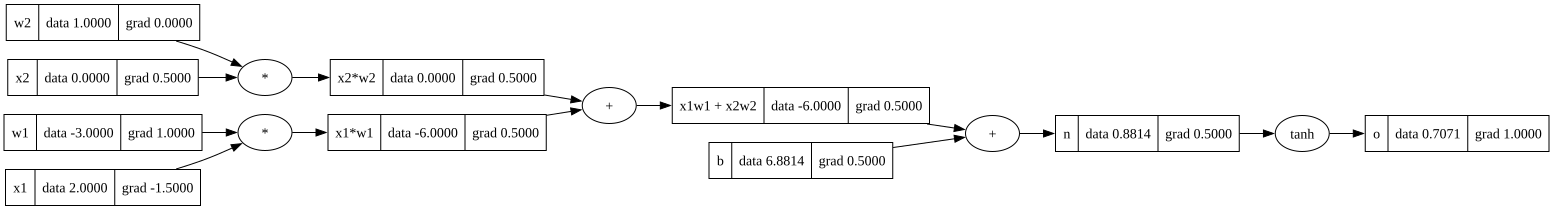

In [82]:
draw_dot(o)


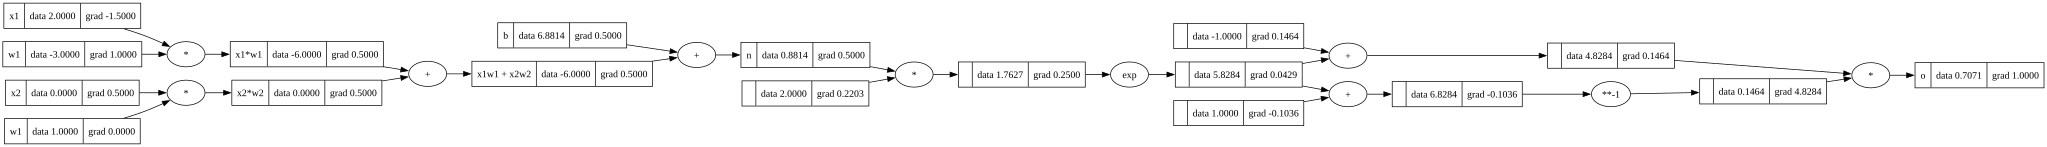

In [ ]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

#weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
#----
e = (2*n).exp()
o =  (e - 1) / (e + 1)
#----
o.label = 'o'
o.backward()
draw_dot(o)

### Doing the same thing in Pytorch 

In [92]:
import torch

x1 = torch.Tensor([2.0]).double(); x1.requires_grad = True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double(); w1.requires_grad = True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double(); b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [94]:
import random

In [131]:
class Neuron:
    
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))
        
    def __call__(self, x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out
    
    def parameters(self):
        return self.w + [self.b]
    
class Layer:
    
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]
        
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
       
    def parameters(self):
        return [p for neuron in self.neurons  for p in neuron.parameters()]

     
class MLP:
    
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
        
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

#x = [2.0, 3.0, -1.0]
#n = MLP(3, [4, 4, 1])
#out = n(x)


In [164]:
# using the XOR dataset for a full training pass

xs = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
]

ys = [-1.0, 1.0, 1.0, -1.0] # desired outputs

epochs = 100

In [ ]:
# training loop with SDG
random.seed(42)     # fixed seed to ensure identical initialization
n = MLP(2, [4, 1])
lr = 0.05
losses_sgd = []

for k in range(epochs):
    
    for p in n.parameters():
        p.grad = 0.0    # to avoid the gradient values accumulating; zero grad
        
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))     #MSE
    losses_sgd.append(loss.data)
    
    # backward pass
    loss.backward()
    
    # update/nudge the neutron parameters ( S. gradient descent step)
    for p in n.parameters():
        p.data += -lr * p.grad
        
    #print(k, loss.data)
print(f"SGD final loss: {losses_sgd[-1]:.6f}")


SGD final loss: 4.485421
SGD final loss: 4.160072
SGD final loss: 4.058617
SGD final loss: 3.976019
SGD final loss: 3.903991
SGD final loss: 3.840635
SGD final loss: 3.784359
SGD final loss: 3.733829
SGD final loss: 3.687947
SGD final loss: 3.645828
SGD final loss: 3.606762
SGD final loss: 3.570183
SGD final loss: 3.535643
SGD final loss: 3.502787
SGD final loss: 3.471334
SGD final loss: 3.441060
SGD final loss: 3.411792
SGD final loss: 3.383390
SGD final loss: 3.355747
SGD final loss: 3.328777
SGD final loss: 3.302416
SGD final loss: 3.276614
SGD final loss: 3.251331
SGD final loss: 3.226539
SGD final loss: 3.202217
SGD final loss: 3.178348
SGD final loss: 3.154923
SGD final loss: 3.131932
SGD final loss: 3.109371
SGD final loss: 3.087236
SGD final loss: 3.065525
SGD final loss: 3.044235
SGD final loss: 3.023366
SGD final loss: 3.002916
SGD final loss: 2.982883
SGD final loss: 2.963266
SGD final loss: 2.944063
SGD final loss: 2.925272
SGD final loss: 2.906888
SGD final loss: 2.888909


In [166]:
# ADAM implementation
random.seed(42)     
n_adam = MLP(2, [4, 1])

# init hyperparameters
lr_adam = 0.05
beta1 = 0.9     # momentum decay rate
beta2 = 0.999   # squared gradient decay rate
eps = 1e-8      # prevents division by zero

# to track state per parameter
m = {p:0 for p in n_adam.parameters()}
v = {p:0 for p in n_adam.parameters()}

losses_adam = []


In [167]:
# training loop
for k in range(epochs):

    for p in n_adam.parameters():
        p.grad = 0.0    # zero grad
        
    ypred = [n_adam(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
    losses_adam.append(loss.data)

    loss.backward()

    for p in n_adam.parameters():
        grad = p.grad
        
        m[p] = beta1 * m[p] + (1 - beta1) * grad            # momentum, running avg of grad
        v[p] = beta2 * v[p] + (1 - beta2)  * (grad**2)      # velocity, running sqrd avg of grad
        
        step = lr_adam * m[p] / (math.sqrt(v[p]) + eps)
        p.data -= step
        
print(f"Adam final loss: {losses_adam[-1]:.6f}")

Adam final loss: 0.000216


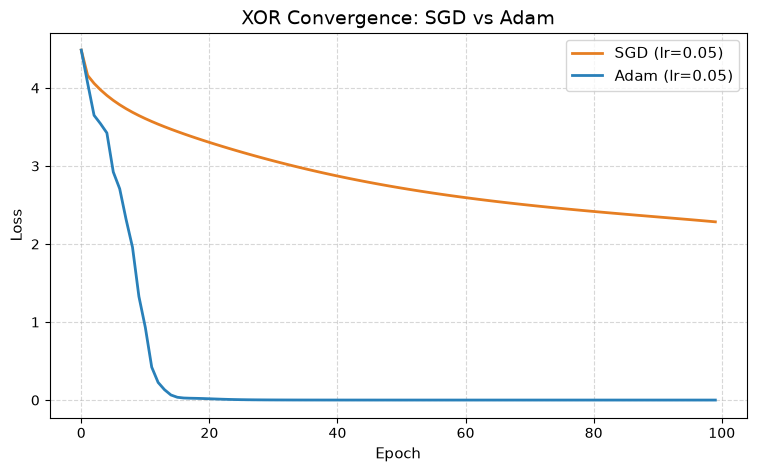

In [168]:
plt.figure(figsize=(9, 5))
plt.plot(losses_sgd, label=f"SGD (lr={lr})", color="#e67e22", linewidth=2)
plt.plot(losses_adam, label=f"Adam (lr={lr_adam})", color="#2980b9", linewidth=2)
plt.title("XOR Convergence: SGD vs Adam", fontsize=14)
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Loss", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)
plt.show()

In [172]:
print(f"{'Input':<12} | {'Target':<8} | {'SGD Pred':<12} | {'Adam Pred':<12}")
print("-" * 52)

for x, y in zip(xs, ys):
    out_sgd = n(x).data
    out_adam = n_adam(x).data
    print(f"{str(x):<12} | {y:<8.1f} | {out_sgd:<12.4f} | {out_adam:<12.4f}")

Input        | Target   | SGD Pred     | Adam Pred   
----------------------------------------------------
[0.0, 0.0]   | -1.0     | -0.7582      | -0.9996     
[0.0, 1.0]   | 1.0      | -0.0365      | 0.9995      
[1.0, 0.0]   | 1.0      | 0.7280       | 0.9887      
[1.0, 1.0]   | -1.0     | 0.0343       | -0.9907     


In [ ]:
n.parameters() # all the weights and biases

17

In [ ]:
ypred

In [138]:
n.layers[0].neurons[0].w[0].grad

-1.3365824197043648

In [140]:
n.layers[0].neurons[0].w[0].data

-0.3372101283940252

In [142]:
n.layers[0].neurons[0].w[0].data

-0.32384430419698157

In [ ]:
draw_dot(loss)

In [118]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
n = MLP(3, [4, 4, 1])
ys = [1.0, -1.0, -1.0, 1.0] # desired targets
ypred = [n(x) for x in xs]
ypred

[Value(data=0.7593346327730773),
 Value(data=0.745073543848358),
 Value(data=0.1434991688464302),
 Value(data=0.8450192622462913)]

In [ ]:
draw_dot(out)

In [ ]:
# implementing a topological sort/tree on the neuron
o.grad = 1.0

topo = []
visited = set()
def build_topo(v):
  if v not in visited:
    visited.add(v)
    for child in v._prev:
      build_topo(child)
    topo.append(v)
build_topo(o)

for node in reversed(topo):
    node._backward()

In [ ]:
o.grad = 1.0

In [ ]:
o._backward()

In [84]:
n._backward()

In [ ]:
n.grad

In [ ]:
b._backward()

In [ ]:
x1w1x2w2._backward()
x2w2._backward()
x1w1._backward()

In [ ]:
b.grad

In [ ]:
x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

In [ ]:
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

In [ ]:
x1w1.grad = 0.5
x2w2.grad = 0.5

In [ ]:
x1w1x2w2.grad = 0.5
b.grad = 0.5

In [ ]:
n.grad = 0.5

In [ ]:
o.grad = 1.0

In [ ]:
n.data